In [1]:
!pip install -q mlflow

In [2]:
import os, glob, re, shutil, time
import numpy as np, pandas as pd
import torch, torch.nn as nn
import mlflow
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORK = "/kaggle/working"

# Fichiers attachés depuis le notebook AI CYBER
found = glob.glob("/kaggle/input/**/ml_dataset.parquet", recursive=True)
print("ml_dataset trouvé :", found)
path = found[0]
df = pd.read_parquet(path).sort_values("ts", kind="mergesort").reset_index(drop=True)

# Mêmes variables que la cellule 3.5 du notebook principal
host_feats = ["hist_flows", "hist_alerted", "hist_alert_rate", "is_new_host",
              "prev1h_flows", "prev1h_alerted", "prev1h_ports"]
cat = ["proto", "app_proto", "state", "reason"]
num = ["dest_port", "pkts_toserver", "pkts_toclient", "bytes_toserver", "bytes_toclient",
       "age", "bytes_ratio", "pkts_total", "hour", "dow", "ip_prev_alerts", "ip_gap_s"] + host_feats

X = pd.get_dummies(df[num + cat], columns=cat, dummy_na=True).astype("float32").fillna(0)
X.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in X.columns]
y = df["label"].values.astype("float32")
assert not any(c.startswith(("signature", "category", "severity", "label")) for c in X.columns)

cut = int(len(df) * 0.8)
print("device :", DEVICE, "| torch", torch.__version__)
print("Lignes :", len(df), "| variables :", X.shape[1], "| train / test :", cut, "/", len(df) - cut)
print("Prévalence train / test :", round(y[:cut].mean(), 3), "/", round(y[cut:].mean(), 3))

ml_dataset trouvé : ['/kaggle/input/notebooks/nawresbm2/ai-cyber/ml_dataset.parquet']
device : cpu | torch 2.11.0+cpu
Lignes : 143807 | variables : 37 | train / test : 115045 / 28762
Prévalence train / test : 0.211 / 0.247


In [3]:


# Préparation spécifique au MLP (version finale, autonome)
# 1) log(1 + x) sur les variables de comptage / taille, dest_port et bytes_ratio
# 2) StandardScaler sur les seules variables numériques, ajusté sur la partie ajustement du train
# 3) colonnes one-hot laissées en 0/1 ; écrêtage à [-5, 5]
dummy_cols = [c for c in X.columns if c.startswith(("proto_", "app_proto_", "state_", "reason_"))]
num_cols = [c for c in X.columns if c not in dummy_cols]
log_cols2 = [c for c in ["pkts_toserver", "pkts_toclient", "bytes_toserver", "bytes_toclient", "age",
                         "pkts_total", "ip_prev_alerts", "ip_gap_s", "hist_flows", "hist_alerted",
                         "prev1h_flows", "prev1h_alerted", "prev1h_ports", "dest_port", "bytes_ratio"]
             if c in X.columns]

vcut = int(cut * 0.8)                      # validation temporelle = 20 % les plus récents du train

# Diagnostic : ce que donnerait une standardisation naïve de toutes les colonnes
naive = StandardScaler().fit(X.iloc[:vcut]).transform(X)
print("Standardisation naïve, colonnes les plus extrêmes (|z| max) :")
print(pd.Series(np.abs(naive).max(axis=0), index=X.columns).sort_values(ascending=False).head(6).round(1).to_string())

Xn = X.copy()
Xn[log_cols2] = np.log1p(Xn[log_cols2].clip(lower=0))
scaler = StandardScaler().fit(Xn[num_cols].iloc[:vcut])
Xn[num_cols] = np.clip(scaler.transform(Xn[num_cols]), -5, 5)
Xs = np.nan_to_num(Xn.values).astype("float32")

X_fit, y_fit = Xs[:vcut], y[:vcut]
X_val, y_val = Xs[vcut:cut], y[vcut:cut]
X_te,  y_te  = Xs[cut:], y[cut:]
print("\nAjustement :", X_fit.shape, "| validation :", X_val.shape, "| test :", X_te.shape)
print("Variables numériques :", len(num_cols), "| one-hot :", len(dummy_cols))
print("Valeurs extrêmes après correction :", round(float(Xs.min()), 1), "/", round(float(Xs.max()), 1))
print("Part des valeurs écrêtées (%) :", round(float((np.abs(Xn[num_cols].values) >= 5).mean() * 100), 2))

Standardisation naïve, colonnes les plus extrêmes (|z| max) :
app_proto_smb     303.399994
app_proto_smtp    303.399994
bytes_ratio       251.100006
bytes_toclient    190.100006
pkts_toclient     189.199997
pkts_total        180.800003

Ajustement : (92036, 37) | validation : (23009, 37) | test : (28762, 37)
Variables numériques : 19 | one-hot : 18
Valeurs extrêmes après correction : -3.6 / 5.0
Part des valeurs écrêtées (%) : 0.03


mlp_small   | AUC-PR validation = 0.899 | époques = 30 | 21 s
mlp_medium  | AUC-PR validation = 0.893 | époques = 11 | 10 s
mlp_large   | AUC-PR validation = 0.895 | époques = 16 | 30 s

Architecture retenue (sur la validation) : mlp_small {'hidden': (64,), 'dropout': 0.1}


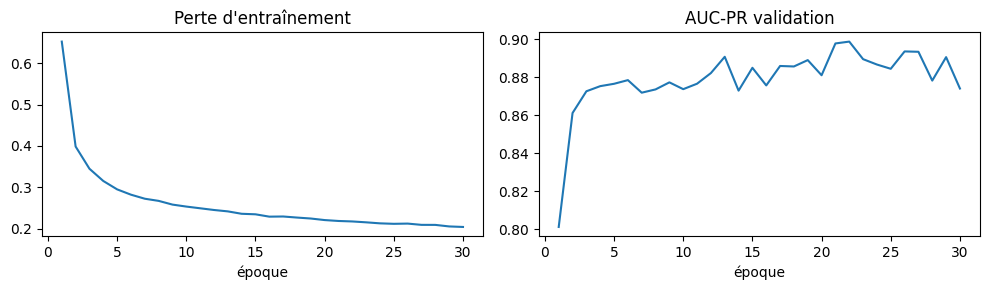

In [4]:
class MLP(nn.Module):
    """Perceptron multicouche : Linear → BatchNorm → ReLU → Dropout, répété, puis 1 sortie (logit)."""
    def __init__(self, d_in, hidden=(128, 64), dropout=0.2):
        super().__init__()
        layers, prev = [], d_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

def predict(model, Xa, bs=8192):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(Xa), bs):
            xb = torch.from_numpy(Xa[i:i + bs]).to(DEVICE)
            out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

def train_mlp(hidden=(128, 64), dropout=0.2, lr=1e-3, wd=1e-4, bs=512, max_epochs=60, patience=8):
    torch.manual_seed(SEED)
    model = MLP(X_fit.shape[1], hidden, dropout).to(DEVICE)
    # Déséquilibre des classes : poids des positifs (équivalent de class_weight="balanced")
    pos_w = torch.tensor(float((1 - y_fit.mean()) / y_fit.mean()), device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    Xt, yt = torch.from_numpy(X_fit), torch.from_numpy(y_fit)

    best_ap, best_state, wait, hist = -1.0, None, 0, []
    for ep in range(max_epochs):
        model.train(); perm = torch.randperm(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:          # BatchNorm exige au moins 2 exemples
                continue
            xb, yb = Xt[idx].to(DEVICE), yt[idx].to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        ap_val = average_precision_score(y_val, predict(model, X_val))
        hist.append((ep + 1, tot / len(Xt), ap_val))
        if ap_val > best_ap + 1e-4:   # early stopping sur l'AUC-PR de VALIDATION
            best_ap, wait = ap_val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_ap, pd.DataFrame(hist, columns=["epoch", "train_loss", "val_auc_pr"])

# 3 architectures comparées sur la VALIDATION (jamais sur le test)
configs = {
    "mlp_small":  dict(hidden=(64,),          dropout=0.1),
    "mlp_medium": dict(hidden=(128, 64),      dropout=0.2),
    "mlp_large":  dict(hidden=(256, 128, 64), dropout=0.3),
}
trained = {}
for name, cfg in configs.items():
    t0 = time.time()
    m, ap_v, h = train_mlp(**cfg)
    trained[name] = (m, ap_v, h, cfg)
    print(f"{name:11s} | AUC-PR validation = {ap_v:.3f} | époques = {len(h)} | {time.time() - t0:.0f} s")

best_name = max(trained, key=lambda k: trained[k][1])
mlp, _, hist_df, best_cfg = trained[best_name]
print("\nArchitecture retenue (sur la validation) :", best_name, best_cfg)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist_df["epoch"], hist_df["train_loss"]); ax[0].set_title("Perte d'entraînement"); ax[0].set_xlabel("époque")
ax[1].plot(hist_df["epoch"], hist_df["val_auc_pr"]); ax[1].set_title("AUC-PR validation"); ax[1].set_xlabel("époque")
plt.tight_layout(); plt.show()

In [5]:
from sklearn.metrics import precision_recall_curve
from lightgbm import LGBMClassifier

def evaluate(y_true, score, pred):
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "auc_pr": average_precision_score(y_true, score),
            "roc_auc": roc_auc_score(y_true, score)}

def thr_for_recall(y_true, score, target=0.90):
    prec, rec, thr = precision_recall_curve(y_true, score)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else 0.5

# --- 1) Comparaison équitable sur la MÊME validation : LightGBM (config défaut) vs MLP ---
lgb = LGBMClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, verbose=-1)
lgb.fit(X.iloc[:vcut], y[:vcut])                       # LightGBM sur les variables brutes (pas besoin de normaliser)
ap_lgb_val = average_precision_score(y_val, lgb.predict_proba(X.iloc[vcut:cut])[:, 1])
print(f"AUC-PR validation (même découpage) | LightGBM = {ap_lgb_val:.3f} | MLP {best_name} = {trained[best_name][1]:.3f}")

# --- 2) Test : seuil du MLP choisi sur la validation (rappel >= 90 %), jamais sur le test ---
THR_MLP = thr_for_recall(y_val, predict(mlp, X_val))
p_te = predict(mlp, X_te)
r_mlp = evaluate(y_te, p_te, (p_te >= THR_MLP).astype(int))
r_mlp05 = evaluate(y_te, p_te, (p_te >= 0.5).astype(int))

# --- 3) MLflow : reprendre la base du run complet pour avoir tous les modèles dans la même expérience ---
src_db = glob.glob("/kaggle/input/**/mlflow.db", recursive=True)
src_art = glob.glob("/kaggle/input/**/mlartifacts", recursive=True)
if src_db and not os.path.exists(f"{WORK}/mlflow.db"):
    shutil.copy(src_db[0], f"{WORK}/mlflow.db")
if src_art and not os.path.exists(f"{WORK}/mlartifacts"):
    shutil.copytree(src_art[0], f"{WORK}/mlartifacts")
mlflow.set_tracking_uri(f"sqlite:///{WORK}/mlflow.db")
if mlflow.get_experiment_by_name("suricata-detection") is None:
    mlflow.create_experiment("suricata-detection", artifact_location=f"{WORK}/mlartifacts")
mlflow.set_experiment("suricata-detection")

with mlflow.start_run(run_name=f"{best_name}_pytorch"):
    mlflow.log_params({"model": "mlp_pytorch", "architecture": best_name,
                       **{k: str(v) for k, v in best_cfg.items()},
                       "preprocessing": "log1p + StandardScaler(num) + clip[-5,5]",
                       "split": "temporal_80_20", "n_features": X_fit.shape[1],
                       "threshold": round(THR_MLP, 4), "epochs": len(hist_df)})
    mlflow.log_metrics({**r_mlp, "val_auc_pr": trained[best_name][1], "lgbm_val_auc_pr_same_split": ap_lgb_val})
    ckpt = {"state_dict": {k: v.cpu() for k, v in mlp.state_dict().items()},
            "config": best_cfg, "features": list(X.columns),
            "num_cols": num_cols, "log_cols": log_cols2, "threshold": THR_MLP,
            "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist()}
    torch.save(ckpt, f"{WORK}/model_mlp.pt", _use_new_zipfile_serialization=False)   # format classique (pas un zip)
    mlflow.log_artifact(f"{WORK}/model_mlp.pt")
    for name, (_, ap_v, h, cfg) in trained.items():          # trace aussi les 3 architectures
        mlflow.log_metric(f"val_auc_pr_{name}", ap_v)

# --- 4) Tableau final avec les modèles du notebook principal ---
prev = glob.glob("/kaggle/input/**/resultats_modeles.csv", recursive=True)
comp = pd.read_csv(prev[0]) if prev else pd.DataFrame()
comp = pd.concat([comp, pd.DataFrame([{"model": f"mlp_{best_name} (seuil {THR_MLP:.3f})", **r_mlp},
                                      {"model": f"mlp_{best_name} (seuil 0,5)", **r_mlp05}])],
                 ignore_index=True)
print("\nSeuil MLP (choisi sur la validation) :", round(THR_MLP, 3))
print("Prévalence du test (AUC-PR sans information) :", round(y_te.mean(), 3))
print(comp.round(3).sort_values("auc_pr", ascending=False).to_string(index=False))
comp.round(4).to_csv(f"{WORK}/resultats_avec_mlp.csv", index=False)

AUC-PR validation (même découpage) | LightGBM = 0.963 | MLP mlp_small = 0.899

Seuil MLP (choisi sur la validation) : 0.672
Prévalence du test (AUC-PR sans information) : 0.247
                      model  precision  recall    f1  auc_pr  roc_auc
              random_forest      0.954   0.861 0.905   0.979    0.992
                   lightgbm      0.915   0.921 0.918   0.977    0.991
             lightgbm_final      0.915   0.921 0.918   0.977    0.991
  mlp_mlp_small (seuil 0,5)      0.805   0.898 0.849   0.945    0.976
mlp_mlp_small (seuil 0.672)      0.867   0.845 0.856   0.945    0.976
                     logreg      0.500   0.730 0.593   0.695    0.845
                   baseline      0.000   0.000 0.000   0.247    0.500
           isolation_forest      0.174   0.250 0.205   0.220    0.488


In [6]:
# Rééchantillonnage des IP (et non des lignes) : les alertes d'une même IP sont corrélées.
p_lgb = LGBMClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, verbose=-1) \
            .fit(X.iloc[:cut], y[:cut]).predict_proba(X.iloc[cut:])[:, 1]
print("Contrôle : AUC-PR test LightGBM recalculée =", round(average_precision_score(y_te, p_lgb), 3), "(attendu 0,977)")

ips = df["src_ip"].iloc[cut:].values
codes, _ = pd.factorize(ips)
idx_by_ip = pd.Series(np.arange(len(ips))).groupby(codes).apply(np.array).values

rng = np.random.RandomState(SEED)
ap_m, ap_l, diff = [], [], []
for b in range(500):
    ii = np.concatenate(idx_by_ip[rng.randint(0, len(idx_by_ip), len(idx_by_ip))])
    if y_te[ii].sum() == 0:
        continue
    a_l, a_m = average_precision_score(y_te[ii], p_lgb[ii]), average_precision_score(y_te[ii], p_te[ii])
    ap_l.append(a_l); ap_m.append(a_m); diff.append(a_l - a_m)

ci = lambda v: np.percentile(v, [2.5, 97.5]).round(3)
print(f"MLP      AUC-PR = {average_precision_score(y_te, p_te):.3f}  IC 95 % {ci(ap_m)}")
print(f"LightGBM AUC-PR = {average_precision_score(y_te, p_lgb):.3f}  IC 95 % {ci(ap_l)}")
print(f"Différence LightGBM − MLP = {np.mean(diff):.3f}  IC 95 % {ci(diff)}")
print("Part des rééchantillonnages où LightGBM bat le MLP :", round(float(np.mean(np.array(diff) > 0)), 3))

with mlflow.start_run(run_name="bootstrap_lgbm_vs_mlp"):
    lo, hi = ci(diff)
    mlflow.log_metrics({"diff_auc_pr_mean": float(np.mean(diff)), "diff_auc_pr_ci_low": float(lo),
                        "diff_auc_pr_ci_high": float(hi)})

Contrôle : AUC-PR test LightGBM recalculée = 0.977 (attendu 0,977)
MLP      AUC-PR = 0.945  IC 95 % [0.914 0.962]
LightGBM AUC-PR = 0.977  IC 95 % [0.956 0.989]
Différence LightGBM − MLP = 0.032  IC 95 % [0.021 0.047]
Part des rééchantillonnages où LightGBM bat le MLP : 1.0


In [7]:
pred_path = glob.glob("/kaggle/input/**/predictions.parquet", recursive=True)[0]
pred = pd.read_parquet(pred_path)
pt = pred[pred["split"] == "test"].copy()          # uniquement des prédictions hors entraînement
print("Alertes de test :", len(pt), "| IP :", pt["src_ip"].nunique())

host = pt.groupby("src_ip").agg(
    n_alerts=("flow_id", "count"), n_flagged=("alert_pred", "sum"),
    n_dest=("dest_ip", "nunique"), n_ports=("dest_port", "nunique"),
    risk_max=("risk", "max"), risk_mean=("risk", "mean"))

# Nouvelle formule (choix de conception, à justifier) :
#  - gravité moyenne des alertes (0-100)        poids 0,4
#  - part des alertes jugées suspectes (0-100)  poids 0,3
#  - volume d'alertes suspectes, en log         poids 0,3  (1 000 alertes suspectes = maximum)
host["flag_rate"] = 100 * host["n_flagged"] / host["n_alerts"]
host["volume"] = 100 * np.minimum(1, np.log10(host["n_flagged"] + 1) / 3)
host["risk_host"] = (0.4 * host["risk_mean"] + 0.3 * host["flag_rate"] + 0.3 * host["volume"]).round(1)
host = host.sort_values(["risk_host", "n_flagged"], ascending=False)

print("\nHôtes avec score >= 99 : ancienne formule (train + test) = voir Phase 6 | nouvelle =",
      int((host["risk_host"] >= 99).sum()))
print("Répartition des scores d'hôte :")
print(pd.cut(host["risk_host"], [0, 20, 40, 60, 80, 90, 100.1], right=False).value_counts().sort_index().to_string())
print("\nTop 10 hôtes (test) :")
print(host.head(10).round(1).to_string())

top5 = host.head(5).index
print("\nSignatures des 5 premiers hôtes :")
print(pt[pt["src_ip"].isin(top5)].groupby(["src_ip", "sig"]).size().sort_values(ascending=False).head(10).to_string())

host.reset_index().to_parquet(f"{WORK}/host_risk_test.parquet", index=False)
with mlflow.start_run(run_name="host_risk_v2"):
    mlflow.log_params({"formule": "0.4*risk_mean + 0.3*flag_rate + 0.3*volume(log10, 1000=max)", "periode": "test"})
    mlflow.log_metrics({"n_hosts": len(host), "n_hosts_ge_99": int((host["risk_host"] >= 99).sum())})
    mlflow.log_artifact(f"{WORK}/host_risk_test.parquet")

Alertes de test : 28762 | IP : 5253

Hôtes avec score >= 99 : ancienne formule (train + test) = voir Phase 6 | nouvelle = 0
Répartition des scores d'hôte :
risk_host
[0.0, 20.0)      3517
[20.0, 40.0)       46
[40.0, 60.0)       93
[60.0, 80.0)     1552
[80.0, 90.0)       44
[90.0, 100.1)       1

Top 10 hôtes (test) :
                 n_alerts  n_flagged  n_dest  n_ports  risk_max  risk_mean  flag_rate  volume  risk_host
src_ip                                                                                                  
165.232.175.249       213        211       1        1      99.8       95.8       99.1    77.5       91.3
185.191.126.213       209        200       1        3     100.0       94.3       95.7    76.8       89.5
80.75.212.75           82         82       1        2     100.0      100.0      100.0    64.0       89.2
152.89.198.175         69         69       1        1     100.0       99.4      100.0    61.5       88.2
138.197.134.93         62         62       1     

In [8]:
chk = torch.load(f"{WORK}/model_mlp.pt", weights_only=False)
print("Clés :", sorted(chk.keys()))
print("Taille :", round(os.path.getsize(f"{WORK}/model_mlp.pt") / 1024, 1), "Ko")
m2 = MLP(len(chk["features"]), **chk["config"]); m2.load_state_dict(chk["state_dict"])
print("Rechargement OK, AUC-PR test :", round(average_precision_score(y_te, predict(m2.to(DEVICE), X_te)), 3))

Clés : ['config', 'features', 'log_cols', 'num_cols', 'scaler_mean', 'scaler_scale', 'state_dict', 'threshold']
Taille : 13.5 Ko
Rechargement OK, AUC-PR test : 0.945
